# Lab 6: FOMO object detection on the XIAO ESP32S3 Sense

Detect, locate and count **blue, green, red and yellow cubes** in one camera frame. FOMO (Faster Objects, More Objects) replaces an image classifier's single answer with a spatial class heatmap. Each output cell predicts background or an object whose **centroid** lies in that cell.

This self-contained teaching implementation uses Edge Impulse's FOMO backbone/head architecture: **MobileNetV2 α=0.35 truncated at `block_6_expand_relu`**, followed by a 32-channel 1×1 head and per-cell classifier. We initialize weights randomly and train on synthetic scenes; this is not EI's pretrained checkpoint or SDK. The centroid loss and decoder remain local teaching implementations. Read [Edge Impulse's FOMO explanation](https://docs.edgeimpulse.com/studio/projects/learning-blocks/blocks/object-detection/fomo) and compare the [Cubes on conveyor belt dataset](https://studio.edgeimpulse.com/public/497627/latest).

**Learning goals:** construct centroid labels, preserve spatial information, balance foreground/background loss, evaluate object detections, export full int8 inference, and interpret detections on the ESP32-S3.

**Hardware:** Seeed XIAO ESP32S3 Sense with camera and PSRAM. The included model is trained on synthetic scenes: use it first with the static image, then investigate the gap to real camera images.

## 1. Environment and contract

Run from this project directory. For local Jupyter, install once with `python -m pip install -r requirements-local.txt` and select that environment as your kernel. For Colab, upload this notebook and `fomo_lab.py`, then run the commented install command **before importing TensorFlow** (restart the runtime if TensorFlow was already imported). Download generated `model/` and `src/` files back to this project afterwards.

The helper module contains dataset generation, the architecture, postprocessing and export functions; inspect it as part of the lab. There are no dataset downloads. Seeds reproduce data and initialization; training may vary slightly between machines.

| Stage | Contract |
| --- | --- |
| Input | `[1, 96, 96, 3]`, RGB normalized to `[0,1]`, then quantized to int8 |
| Output | `[1, 12, 12, 5]`, int8 per-cell softmax probabilities |
| Channel order | background, blue, green, red, yellow |
| Coordinates | input pixels, top-left origin; x right, y down |
| Decoder | argmax, probability ≥ 0.60, same-class 4-connected components |

Do not feed raw 0–255 floats or copy bytes into a float tensor. Firmware reads the model's quantization parameters and checks this contract at startup.

In [1]:
# Colab only, before the imports below:
# %pip install tensorflow==2.19.1 tf-keras==2.19.0 'numpy>=1.26,<2' pillow matplotlib
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import fomo_lab as lab

# Small CPU thread pools also work well on classroom laptops.
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(42)
print('TensorFlow:', tf.__version__)
Path('model').mkdir(exist_ok=True)
print('Classes:', lab.CLASS_NAMES)

TensorFlow: 2.19.1
Classes: ('background', 'blue', 'green', 'red', 'yellow')


## 2. Generate independent training, validation and test scenes

Each scene has 0–5 cubes on a textured dark conveyor belt. Randomize color brightness, location, size, shading and noise. Include empty scenes so the network learns background. Images are reduced to RGB565 precision and expanded again to match camera preprocessing.

Generate splits with **different random seeds before shuffling**. The validation set chooses training duration; the test set is reserved for final float/int8 evaluation. This avoids the old `take/skip` split of a reshuffled stream, which could mix samples between splits.

Annotations are `(class_id, x, y, width, height)` in input pixels. Their centroids, rather than their full boxes, supervise the detector. Synthetic data is useful for learning the pipeline; good real-world detection requires representative camera data.

Images: (1200, 96, 96, 3) (240, 96, 96, 3) (240, 96, 96, 3)
Training empty frames: 181
Foreground cells: 3007 / 172800


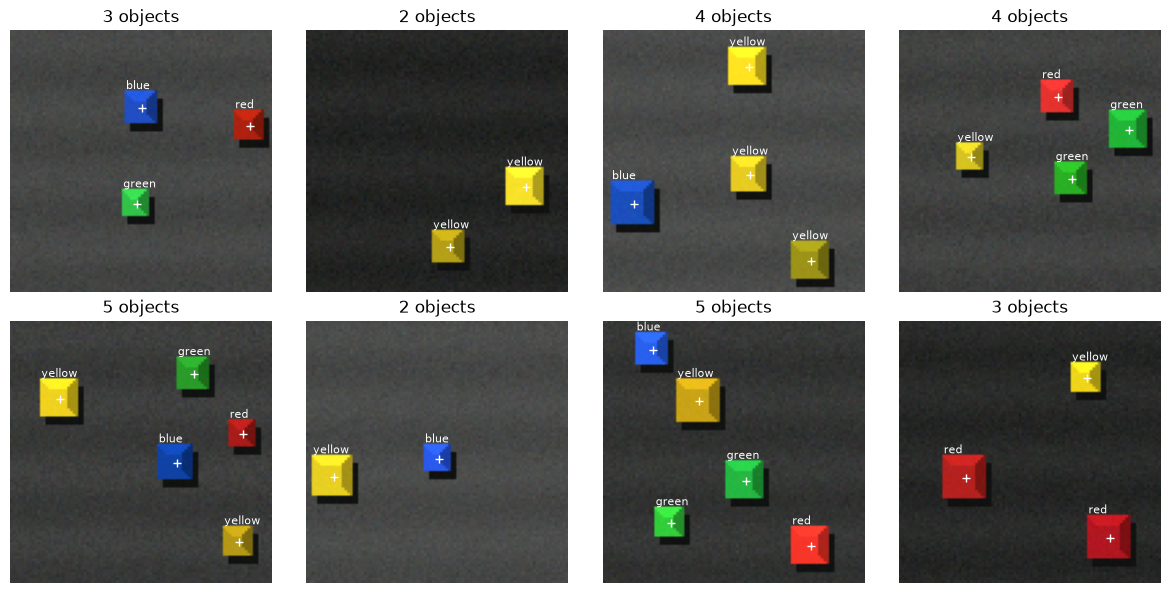

In [2]:
train_images, train_boxes = lab.make_dataset(1200, seed=100)
val_images, val_boxes = lab.make_dataset(240, seed=200)
test_images, test_boxes = lab.make_dataset(240, seed=300)
train_targets = lab.centroid_targets(train_boxes)
val_targets = lab.centroid_targets(val_boxes)
test_targets = lab.centroid_targets(test_boxes)
print('Images:', train_images.shape, val_images.shape, test_images.shape)
print('Training empty frames:', sum(not boxes for boxes in train_boxes))
print('Foreground cells:', np.count_nonzero(train_targets), '/', train_targets.size)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, boxes in zip(axes.flat, train_images, train_boxes):
    ax.imshow(image)
    for cid, x, y, w, h in boxes:
        ax.plot(x + w / 2, y + h / 2, 'w+')
        ax.text(x, y - 1, lab.CLASS_NAMES[cid], color='white', fontsize=8)
    ax.set_title(f'{len(boxes)} objects')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Encode centroid targets and preserve space

A stride of 8 maps `(cx, cy)` to `(floor(cx/8), floor(cy/8))`. Class 0 fills the remaining cells. The model must learn to place one activation near each center, rather than segment the entire cube.

Two centroids in one cell cannot be represented. Adjacent activations of the same color also merge under this lab's decoder. The generator keeps centers at least 24 pixels apart; later exercises deliberately violate that assumption.

MobileNetV2's early stages reduce 96→48→24→12. Its inverted residual blocks use 1×1 expansion, 3×3 depthwise convolution, and 1×1 linear projection, with batch normalization, ReLU6 and residual additions. We cut at **`block_6_expand_relu`**, before block 6 downsamples again: with α=0.35 the retained features are **12×12×96**. A **1×1 Conv(32, ReLU) → 1×1 Conv(5) → softmax** head predicts each cell. There is no Flatten, Dense, or global pooling.

`weights=None` keeps the lab offline and trains all retained layers from scratch. MobileNetV2's batch-normalization momentum is set to 0.9 so moving statistics adapt to this small dataset. Inputs remain `[0,1]`; ImageNet `[-1,1]` preprocessing is not applied because ImageNet weights are not used. Replacing this initialization with pretrained weights would require revisiting preprocessing and fine-tuning.

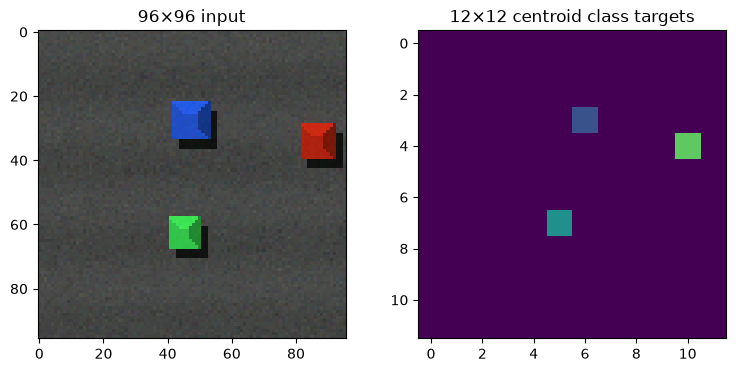

Retained features: (None, 12, 12, 96)
Model: "fomo_mobilenetv2_cubes"


__________________________________________________________________________________________________


 Layer (type)                Output Shape                 Param #   Connected to                  


 rgb_0_to_1 (InputLayer)     [(None, 96, 96, 3)]          0         []                            


 Conv1 (Conv2D)              (None, 48, 48, 16)           432       ['rgb_0_to_1[0][0]']          


...

 x)                                                                                               


Total params: 20853 (81.46 KB)


Trainable params: 19109 (74.64 KB)


Non-trainable params: 1744 (6.81 KB)


__________________________________________________________________________________________________


In [3]:
index = next(i for i, boxes in enumerate(train_boxes) if len(boxes) >= 3)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(train_images[index])
axes[0].set_title('96×96 input')
axes[1].imshow(train_targets[index], vmin=0, vmax=4, interpolation='nearest')
axes[1].set_title('12×12 centroid class targets')
plt.show()

model = lab.build_model(tf)
print('Retained features:', model.get_layer(lab.BACKBONE_CUT_POINT).output_shape)
assert model.get_layer(lab.BACKBONE_CUT_POINT).output_shape == (None, 12, 12, 96)
assert model.output_shape == (None, 12, 12, 5)
model.summary()

## 4. Balance foreground loss and train

Most cells are background, so raw cell accuracy can look excellent even when every object is missed. Weight foreground cross-entropy by 20, background by 1. The value is a lab hyperparameter: raising it can improve recall while increasing false positives. Only validation data should guide such choices.

Inputs are normalized outside the model. The same `/255` operation is used before int8 quantization in firmware. Loss uses probabilities (`from_logits=False`) because the output includes softmax.

Epoch 1/40


38/38 - 5s - loss: 1.0259 - val_loss: 1.1644 - 5s/epoch - 132ms/step


Epoch 2/40


38/38 - 3s - loss: 0.1318 - val_loss: 0.0751 - 3s/epoch - 74ms/step


Epoch 3/40


...

38/38 - 3s - loss: 0.0014 - val_loss: 0.0213 - 3s/epoch - 79ms/step


Epoch 34/40


38/38 - 3s - loss: 0.0015 - val_loss: 0.0280 - 3s/epoch - 80ms/step


Epoch 35/40


38/38 - 3s - loss: 0.0011 - val_loss: 0.0261 - 3s/epoch - 82ms/step


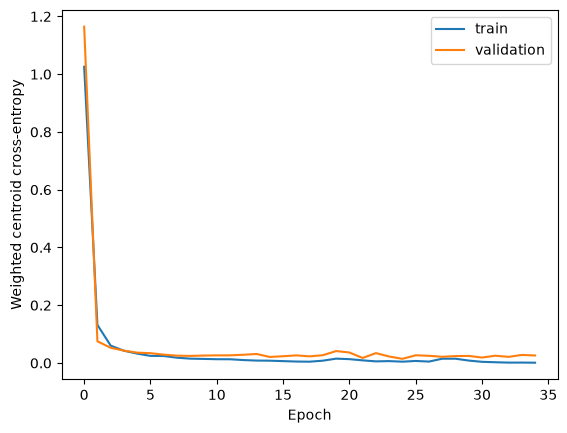

In [4]:
OBJECT_WEIGHT = 20.0
EPOCHS = 40
BATCH_SIZE = 32

def centroid_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    weights = tf.where(y_true == 0, 1.0, OBJECT_WEIGHT)
    return ce * weights

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=centroid_loss)
options = tf.data.Options()
options.threading.private_threadpool_size = 2
train_ds = (tf.data.Dataset.from_tensor_slices(
    (train_images.astype(np.float32) / 255., train_targets))
    .shuffle(len(train_images), seed=42).batch(BATCH_SIZE).with_options(options))
val_ds = (tf.data.Dataset.from_tensor_slices(
    (val_images.astype(np.float32) / 255., val_targets))
    .batch(BATCH_SIZE).with_options(options))
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=[tf.keras.callbacks.CSVLogger('model/training-history.csv'),
                               tf.keras.callbacks.EarlyStopping(
                        monitor='val_loss', patience=10, restore_best_weights=True)], verbose=2)
model.save_weights('model/fomo.weights.h5')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.xlabel('Epoch')
plt.ylabel('Weighted centroid cross-entropy')
plt.legend()
plt.show()

## 5. Turn heatmaps into detections

For each cell, take its highest-probability class. Discard background and confidence below 0.60. Merge **4-connected cells of the same class**, emitting one detection with confidence-weighted cell-center coordinates and peak confidence. The Python helper and C++ `FomoDecoder.h` implement the same policy; it is a teaching decoder rather than a copy of the Edge Impulse SDK.

The stride limits localization: a cell center is at `(8x+4, 8y+4)`. Detections provide class, location and count; they do **not** estimate physical object dimensions. Touching same-class activations can merge distinct objects.

The validation table below shows the precision/recall tradeoff. Keep the default threshold for the supplied firmware; if you choose a new threshold, change `lab.THRESHOLD` before export and repeat evaluation.

threshold=0.4 precision=1.000 recall=1.000 F1=1.000
threshold=0.6 precision=0.997 recall=1.000 F1=0.998
threshold=0.8 precision=0.998 recall=1.000 F1=0.999


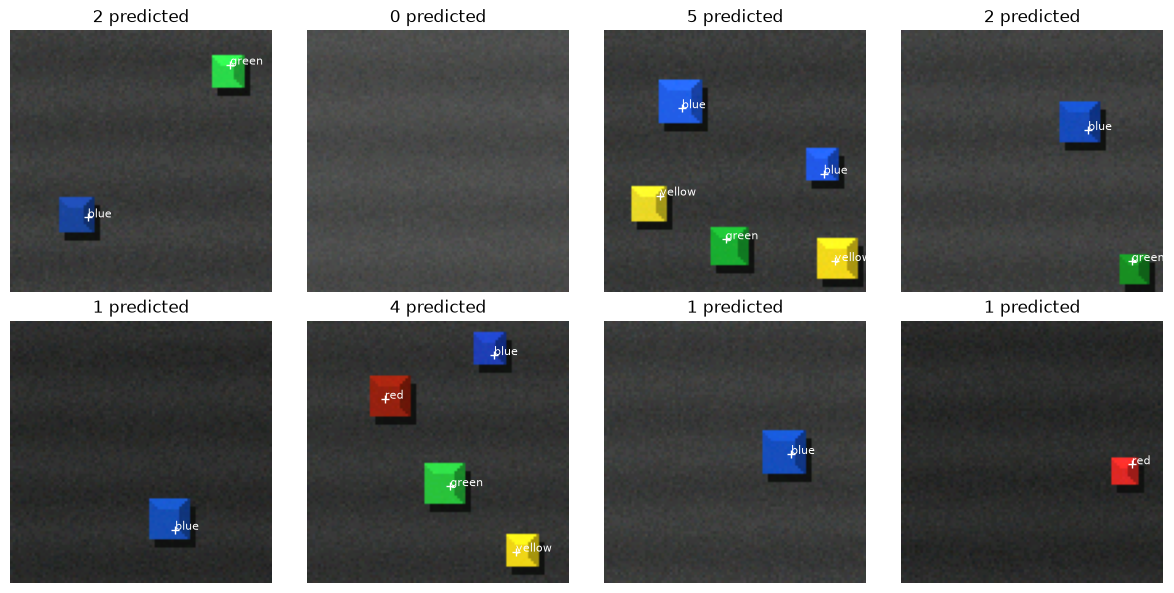

In [5]:
val_probabilities = model.predict(val_images.astype(np.float32) / 255., batch_size=32, verbose=0)
for threshold in (0.4, 0.6, 0.8):
    metrics = lab.detection_metrics(val_probabilities, val_boxes, threshold=threshold)
    print(f"threshold={threshold:.1f} precision={metrics['precision']:.3f} "
          f"recall={metrics['recall']:.3f} F1={metrics['f1']:.3f}")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, heatmap in zip(axes.flat, val_images, val_probabilities):
    ax.imshow(image)
    detections = lab.decode_heatmap(heatmap)
    for det in detections:
        ax.plot(det['x'], det['y'], 'w+')
        ax.text(det['x'], det['y'], lab.CLASS_NAMES[det['class_id']], color='white', fontsize=8)
    ax.set_title(f'{len(detections)} predicted')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Export genuine integer-only TensorFlow Lite

Calibration uses **training images only**, in the same normalized range used for training. Request int8 input and output explicitly and restrict conversion to integer built-in operators. Dynamic-range quantization alone does not guarantee integer inference.

Keep a float TFLite model for comparison. Conversion and evaluation require no `xxd`, shell substitutions or Edge Impulse account.

Conversion folds batch normalization into convolution parameters and fuses ReLU6 and explicit padding into the convolution kernels where possible. The exported MobileNetV2 model needs Conv2D, DepthwiseConv2D, Add and Softmax kernels in firmware. The firmware first requests a 280 KiB, 16-byte-aligned tensor arena in internal SRAM, based on the measured 270,460-byte use plus about 16 KiB headroom. It prints free internal SRAM, the largest free block and actual arena use. One contiguous internal block must be available; otherwise the firmware falls back to an aligned PSRAM arena. The startup message identifies the actual memory used. Failure of both allocations stops inference. Recheck the budget after model or kernel changes.

In [6]:
float_converter = tf.lite.TFLiteConverter.from_keras_model(model)
float_bytes = float_converter.convert()
Path('model/fomo-float32.tflite').write_bytes(float_bytes)

def representative_data():
    for image in train_images[:160]:
        yield [image[None].astype(np.float32) / 255.]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8
int8_bytes = converter.convert()
Path('model/fomo-int8.tflite').write_bytes(int8_bytes)
print('Float bytes:', len(float_bytes), 'Int8 bytes:', len(int8_bytes))

int8_probabilities, input_detail, output_detail = lab.tflite_predict(tf, int8_bytes, test_images)
print('Input:', input_detail['shape'], input_detail['dtype'], input_detail['quantization'])
print('Output:', output_detail['shape'], output_detail['dtype'], output_detail['quantization'])
# Enforce that inference tensors are integer (int32 bias tensors are expected).
check = tf.lite.Interpreter(model_content=int8_bytes)
check.allocate_tensors()
assert all(t['dtype'] != np.float32 for t in check.get_tensor_details())
operators = sorted({op['op_name'] for op in check._get_ops_details()} - {'DELEGATE'})
assert set(operators) == {'CONV_2D', 'DEPTHWISE_CONV_2D', 'ADD', 'SOFTMAX'}
print('Operators:', operators)

INFO:tensorflow:Assets written to: /var/folders/2_/kskwshj16hqb0586p6cydg4h0000gq/T/tmpcvehuu1s/assets


INFO:tensorflow:Assets written to: /var/folders/2_/kskwshj16hqb0586p6cydg4h0000gq/T/tmpcvehuu1s/assets


W0000 00:00:1793235158.722629 27048046 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.


W0000 00:00:1793235158.722932 27048046 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1793235158.761523 27048046 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled


INFO:tensorflow:Assets written to: /var/folders/2_/kskwshj16hqb0586p6cydg4h0000gq/T/tmpoeh7yxr8/assets


INFO:tensorflow:Assets written to: /var/folders/2_/kskwshj16hqb0586p6cydg4h0000gq/T/tmpoeh7yxr8/assets


/Users/h488y928/Projects/EmbeddedML/l6-fomo/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793235162.020286 27048046 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1793235162.020309 27048046 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.


Float bytes: 84564 Int8 bytes: 56328
Input: [ 1 96 96  3] <class 'numpy.int8'> (0.003921568859368563, -128)
Output: [ 1 12 12  5] <class 'numpy.int8'> (0.00390625, -128)
Operators: ['ADD', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'SOFTMAX']


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
/Users/h488y928/Projects/EmbeddedML/l6-fomo/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## 7. Evaluate once on the held-out test set

For float and int8 TFLite, decode the same held-out scenes. A true positive must match an unmatched ground-truth centroid of the **same class within 8 input pixels**. Match predictions from highest to lowest confidence; count unmatched predictions as false positives and unmatched ground truth as false negatives.

Report precision, recall, F1, exact per-class counts per frame, and the mean sum of absolute per-class count errors. Empty frames contribute to the count metric and false-positive assessment. These are synthetic-scene results, not a claim about real conveyor belts. Cell accuracy is intentionally omitted.

In [7]:
float_interpreter = tf.lite.Interpreter(model_content=float_bytes, num_threads=1)
float_interpreter.allocate_tensors()
fi, fo = float_interpreter.get_input_details()[0], float_interpreter.get_output_details()[0]
float_probabilities = []
for image in test_images:
    float_interpreter.set_tensor(fi['index'], image[None].astype(np.float32) / 255.)
    float_interpreter.invoke()
    float_probabilities.append(float_interpreter.get_tensor(fo['index'])[0])
float_metrics = lab.detection_metrics(float_probabilities, test_boxes)
int8_metrics = lab.detection_metrics(int8_probabilities, test_boxes)
report = dict(architecture=dict(backbone='MobileNetV2', alpha=lab.BACKBONE_ALPHA,
                               cut_point=lab.BACKBONE_CUT_POINT, weights='random',
                               batch_norm_momentum=0.9, parameters=model.count_params(),
                               tflite_operators=operators),
              model_bytes=dict(float32=len(float_bytes), int8=len(int8_bytes)),
              dataset='synthetic cubes v1', seeds=dict(train=100, validation=200, test=300),
              split_sizes=dict(train=len(train_images), validation=len(val_images), test=len(test_images)),
              threshold=lab.THRESHOLD, matching_radius_pixels=8,
              epochs_run=len(history.history['loss']), float32=float_metrics, int8=int8_metrics)
Path('model/metrics.json').write_text(json.dumps(report, indent=2) + '\n')
print(json.dumps(report, indent=2))

{
  "architecture": {
    "backbone": "MobileNetV2",
    "alpha": 0.35,
    "cut_point": "block_6_expand_relu",
    "weights": "random",
    "batch_norm_momentum": 0.9,
    "parameters": 20853,
    "tflite_operators": [
      "ADD",
      "CONV_2D",
      "DEPTHWISE_CONV_2D",
      "SOFTMAX"
    ]
  },
  "model_bytes": {
    "float32": 84564,
    "int8": 56328
  },
  "dataset": "synthetic cubes v1",
  "seeds": {
    "train": 100,
    "validation": 200,
    "test": 300
  },
  "split_sizes": {
    "train": 1200,
    "validation": 240,
    "test": 240
  },
  "threshold": 0.6,
  "matching_radius_pixels": 8,
  "epochs_run": 35,
  "float32": {
    "tp": 601,
    "fp": 0,
    "fn": 0,
    "precision": 1.0,
    "recall": 1.0,
    "f1": 1.0,
    "exact_class_counts": 1.0,
    "mean_absolute_class_count_error": 0.0,
    "per_class": {
      "blue": {
        "tp": 144,
        "fp": 0,
        "fn": 0
      },
      "green": {
        "tp": 141,
        "fp": 0,
        "fn": 0
      },
      "r

## 8. Generate the firmware model and static input together

This cell replaces `src/model.cc`, `src/model_config.h`, and `src/img.h`. The configuration stores shape, labels, threshold and quantization from this exact model. `model.h` declares the array; compile `model.cc` separately rather than including it in another `.cpp`.

The static example is a held-out image containing multiple objects, selected by its annotations (not by model success). The saved JSON gives expected desktop detections. On the board, `FOMO_STATIC_IMAGE=1` bypasses the camera and copies the exact quantized input into the tensor. Small quantized-kernel differences can occur; compare class/count and coordinates within roughly one cell.

In [8]:
example_index = next(i for i, boxes in enumerate(test_boxes) if len(boxes) >= 3)
expected = lab.export_firmware(int8_bytes, input_detail, output_detail,
                               test_images[example_index], int8_probabilities[example_index])
from PIL import Image
Image.fromarray(test_images[example_index]).save('model/static-input.png')
print('Static-image ground truth:', test_boxes[example_index])
print('Expected int8 detections:', json.dumps(expected, indent=2))
print('Generated model.cc, model_config.h, img.h and model/static-* artifacts')

Static-image ground truth: [(4, 11, 69, 11, 11), (3, 51, 52, 15, 15), (4, 27, 43, 14, 14), (4, 65, 27, 15, 15)]
Expected int8 detections: [
  {
    "class_id": 4,
    "x": 76.0,
    "y": 36.0,
    "score": 0.99609375
  },
  {
    "class_id": 4,
    "x": 36.0,
    "y": 52.0,
    "score": 0.99609375
  },
  {
    "class_id": 3,
    "x": 60.0,
    "y": 60.0,
    "score": 0.99609375
  },
  {
    "class_id": 4,
    "x": 20.0,
    "y": 76.0,
    "score": 0.99609375
  }
]
Generated model.cc, model_config.h, img.h and model/static-* artifacts


## 9. Build and run on the ESP32-S3

From a terminal in this directory:

```sh
pio run -e seeed_xiao_esp32s3_static
pio run -e seeed_xiao_esp32s3_static -t upload
pio device monitor -b 115200
```

Compare the printed class, confidence and `(x,y)` with `model/static-expected.json`. The static environment does not need the camera. It uses the real TensorFlow Lite Micro interpreter with the tensor arena preferably in internal SRAM, falling back to PSRAM if necessary. The camera build uses PSRAM for its framebuffer.

Then build/upload `seeed_xiao_esp32s3` to enable the camera. Capture RGB565 at 96×96, expand to RGB and quantize `q = clamp(floor((pixel/255)/scale + zero_point + 0.5))`. The LED is active-low and lights when any cube is detected. Serial prints class counts **per frame**, centroids, and preprocessing/inference times. Repeated frames do not represent unique conveyor throughput; that would require tracking or line crossing.

At startup the firmware checks model schema, allocation, tensor dimensions, dtypes and quantization. Allocation or camera failure stops inference safely. Detections use a fixed-capacity queue bounded by the grid size. Every acquired camera frame is returned, including on preprocessing failure.

## 10. Experiments and submission

1. Explain why a 12×12×5 output can count several objects while a single sigmoid cannot.
2. Compare foreground weights 1, 20 and 100 using validation data. Why can background cell accuracy be misleading?
3. Put two same-color objects in adjacent cells, and two centroids in one cell. Explain the two different failure modes. Try cutting MobileNetV2 at `block_3_expand_relu` for stride 4; update the configuration and decoder consistently.
4. Compare float/int8 F1, model bytes, measured on-device arena use and inference latency. Do not report desktop timing as device timing.
5. Photograph actual cubes from the deployment camera at several distances and lighting conditions. Replace synthetic examples with annotated real images and repeat the split/train/evaluate/export workflow. If importing the linked Edge Impulse dataset, preserve its training/test split, center-crop to square and resize to 96×96 while transforming/clipping boxes with the **same geometry**; discard boxes whose object center falls outside the crop. Train/validation splitting should group nearby conveyor frames to avoid scene leakage. The provided generator needs no external dataset importer.

Submit the executed notebook, detection metrics, firmware serial output from static and live runs, and a discussion of real-camera failure cases. Explain the assumptions about cube size, separation and background before drawing conclusions about deployment.